
20m  f0=14.00 MHz  BW=3.0 kHz  PEP=32.17 dBm  S11<=-20.0, S21int>=-0.5

--- LMatch_WB2CBA (Textbook) ---
  Lm= 210.7nH  Cm=  512.5pF  C1=  266.3pF  L2= 720.1nH  C3=  442.0pF  L4= 720.1nH  C5=  266.3pF

  LMatch ideal ... done
  LMatch real (seeded from textbook) ... done
  JA2GQP ideal ... done
  JA2GQP real (seeded) ... done
  4Element ideal ... done
  4Element real (seeded) ... done

--- LMatch_WB2CBA (Ideal Opt) ---
  Lm= 421.1nH  Cm= 1021.1pF  C1=  520.2pF  L2= 416.1nH  C3=  518.6pF  L4=1435.4nH  C5=  531.6pF

--- LMatch_WB2CBA (Real Opt) ---
  Lm= 264.6nH  Cm=  464.0pF  C1=  228.4pF  L2= 577.1nH  C3=  882.7pF  L4= 377.7nH  C5=  532.2pF

--- JA2GQP (Ideal Opt) ---
  C1= 1500.0pF  L2= 700.0nH  C2=   46.2pF  C3=  387.1pF  L4= 550.2nH  C4=   26.1pF  C5= 1500.0pF

--- JA2GQP (Real Opt) ---
  C1= 1500.0pF  L2= 126.7nH  C2=  249.3pF  C3= 1500.0pF  L4= 329.3nH  C4=   43.0pF  C5=  529.7pF

--- 4Element (Ideal Opt) ---
  C1= 3000.0pF  L2=  93.5nH  C2=  345.7pF  C3= 1441.3pF

--- 4Element (

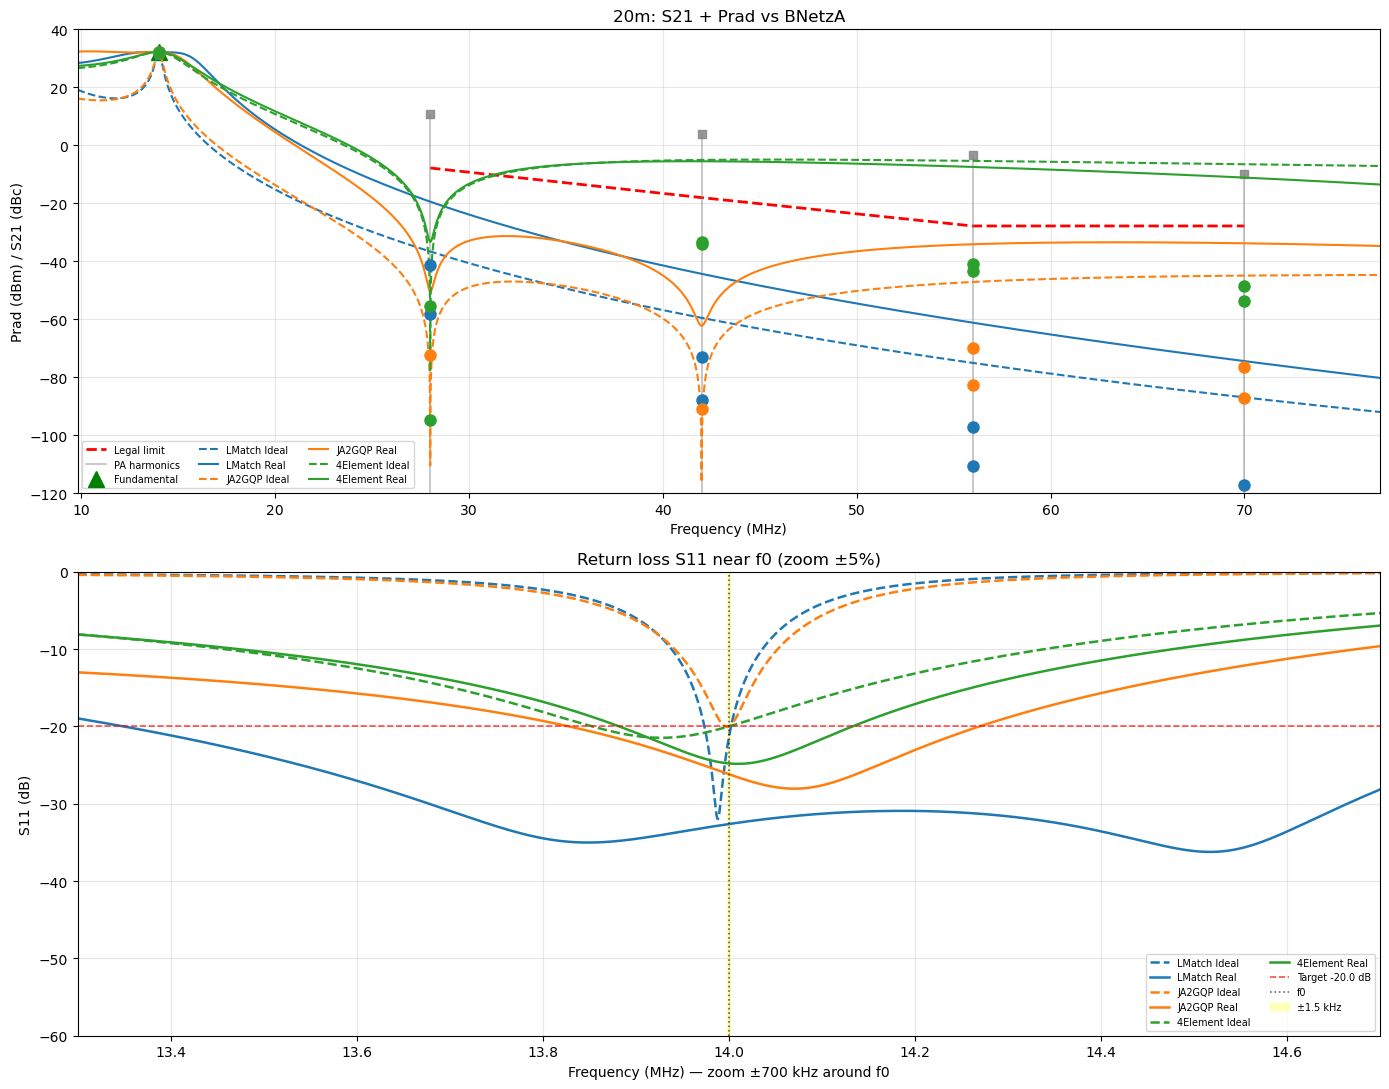

 done

40m  f0=7.00 MHz  BW=3.0 kHz  PEP=32.17 dBm  S11<=-20.0, S21int>=-0.5

--- LMatch_WB2CBA (Textbook) ---
  Lm= 421.4nH  Cm= 1025.0pF  C1=  532.6pF  L2=1440.1nH  C3=  884.0pF  L4=1440.1nH  C5=  532.6pF

  LMatch ideal ... done
  LMatch real (seeded from textbook) ... done
  JA2GQP ideal ... done
  JA2GQP real (seeded) ... done
  4Element ideal ... done
  4Element real (seeded) ... done

--- LMatch_WB2CBA (Ideal Opt) ---
  Lm= 842.2nH  Cm= 2042.1pF  C1= 1040.4pF  L2= 832.3nH  C3= 1037.2pF  L4=2870.8nH  C5= 1063.2pF

--- LMatch_WB2CBA (Real Opt) ---
  Lm= 309.9nH  Cm= 1714.2pF  C1=  267.1pF  L2= 720.4nH  C3= 1532.3pF  L4= 885.6nH  C5=  716.0pF

--- JA2GQP (Ideal Opt) ---
  C1= 1500.0pF  L2= 300.2nH  C2=  430.5pF  C3= 1500.0pF  L4= 700.0nH  C4=   82.1pF  C5=  388.9pF

--- JA2GQP (Real Opt) ---
  C1= 1500.0pF  L2= 301.1nH  C2=  424.9pF  C3= 1500.0pF  L4= 700.0nH  C4=   81.4pF  C5=  372.6pF

--- 4Element (Ideal Opt) ---
  C1= 3000.0pF  L2= 288.7nH  C2=  447.7pF  C3= 1721.1pF

--- 4Elem

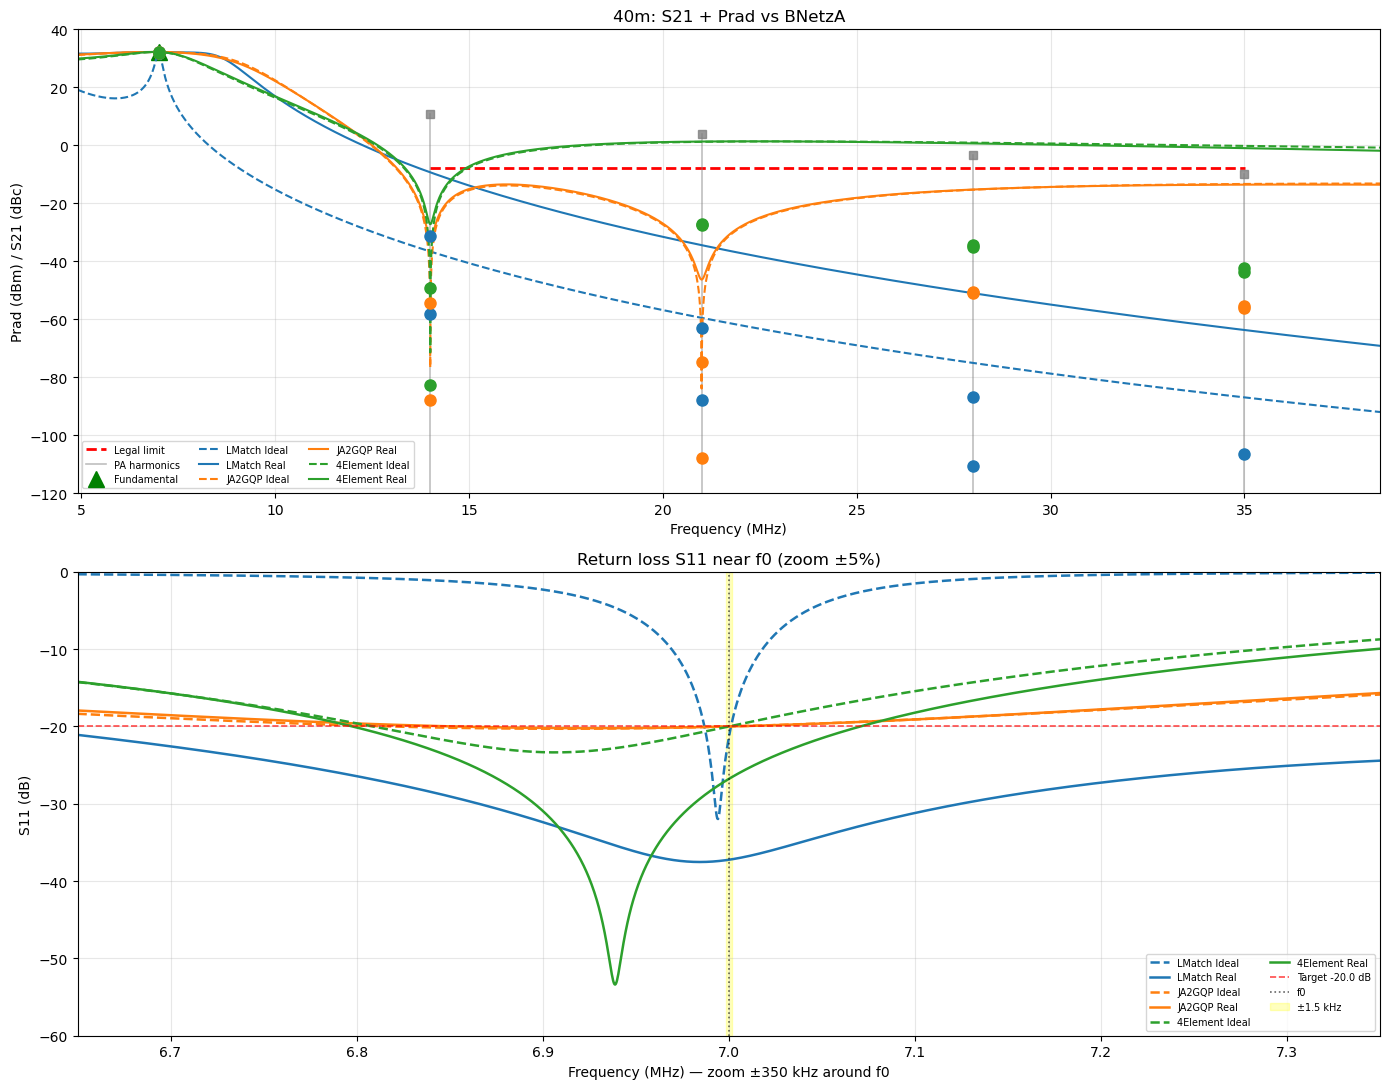

 done

DONE.


In [12]:
#!/usr/bin/env python3
"""unified_pa_design_v8.py

Changes vs v7:
- S11 subplot zooms to f0 ± 5% (was full band, unreadable)
- S11 y-axis auto-scales to the data (typically -60..0 dB)
- VSWR column added to the table
- f0 marked with vertical line on the S11 zoom
"""
import math
import warnings
import numpy as np
from scipy.optimize import differential_evolution, NonlinearConstraint
import matplotlib.pyplot as plt

V_DD, P_out, R_ant = 4.85, 1.65, 50.0
PEP_W = P_out
C_OSS_EPC2037 = 12e-12
Q_L = 3.0
BANDS = [{'name': '20m', 'f0': 14.0e6}, {'name': '40m', 'f0': 7.0e6}]
BW_MODULATION = 3000.0

S11_MAX_DB      = -20.0
S21_MIN_DB      = -0.5
LOW_CAP_WARN_PF = 30.0
S11_PLOT_SPAN_PCT = 0.05    # ±5% of f0 for the S11 zoom

Q_PEAK  = 90.0
F_QPEAK = 20e6

TRACE_L_NH = 2.0
CAP_ESL_NH = 0.8

PA_HARMONICS_DBC = {2: -21.5, 3: -28.2, 4: -35.4, 5: -42.1}

# ============================================================
# BNetzA
# ============================================================
def bnetza_limit_dbc(freq_hz, pep_w):
    f_mhz = freq_hz / 1e6
    if f_mhz <= 1.7:     att = 60.0
    elif f_mhz <= 35.0:  att = 40.0
    elif f_mhz <= 50.0:
        frac = math.log10(f_mhz/35.0) / math.log10(50.0/35.0)
        att = 40.0 + 20.0*frac
    elif f_mhz <= 1000.0: att = 60.0
    else:                  att = 50.0
    return -att

def bnetza_absolute_limit_dbm(freq_hz):
    f_mhz = freq_hz / 1e6
    if 35.0 < f_mhz <= 50.0:     return -36.0
    elif 50.0 < f_mhz <= 1000.0: return -30.0
    return None

def bnetza_limit_dbm(freq_hz, pep_w):
    pep_dbm = 10*math.log10(pep_w*1000.0)
    rel = pep_dbm + bnetza_limit_dbc(freq_hz, pep_w)
    abs_ = bnetza_absolute_limit_dbm(freq_hz)
    return rel if abs_ is None else max(rel, abs_)

# ============================================================
# Components
# ============================================================
def inductor_srf_hz(L):
    return 300e3 / math.sqrt(L)

def inductor_cp(L):
    srf = inductor_srf_hz(L)
    return 1.0 / ((2.0*math.pi*srf)**2 * L)

def derive_notch_cap(L, f_target, ideal):
    w = 2.0 * math.pi * f_target
    if ideal:
        return 1.0 / (w*w * L)
    Cp = inductor_cp(L)
    L_eff = L / (1.0 - w*w*L*Cp) + TRACE_L_NH*1e-9
    return max(1.0 / (w*w * (L_eff + CAP_ESL_NH*1e-9)), 1e-15)

def make_inductor(L):
    SRF = inductor_srf_hz(L)
    Cp  = 1.0 / ((2.0*math.pi*SRF)**2 * L)
    def Z(f):
        w = 2.0*math.pi*f
        x = f / F_QPEAK
        if x < 1e-6:
            Q_f = Q_PEAK * 1e-6
        else:
            Q_f = Q_PEAK * 2.0 * x / (1.0 + x*x)
        Rs = (w*L) / max(Q_f, 1.0)
        d = 1.0 - w*w*L*Cp
        ZL = 1e12j if abs(d) < 1e-14 else 1j*w*L/d
        return ZL + Rs + 1j*w * (TRACE_L_NH*1e-9)
    return Z

def make_cap(C, ESL=CAP_ESL_NH*1e-9):
    def Z(f):
        w = 2.0*math.pi*f
        return 1.0/(1j*w*C) + 1j*w*ESL
    return Z

def _series(Z): return np.array([[1, Z], [0, 1]], dtype=complex)
def _shunt(Y):  return np.array([[1, 0], [Y, 1]], dtype=complex)

def _s_from_abcd(M, R_in, R_out):
    A, B = M[0,0], M[0,1]
    C, D = M[1,0], M[1,1]
    d = A + B/R_out + C*R_in + D*R_in/R_out
    return ((A + B/R_out - C*R_in - D*R_in/R_out)/d,
            2.0*math.sqrt(R_in/R_out)/d)

# ============================================================
# Builders / Assemblers
# ============================================================
def _build_lmatch(vals, ideal):
    if ideal: return {k: vals[k] for k in ('Lm','Cm','C1','L2','C3','L4','C5')}
    return dict(Lm=make_inductor(vals['Lm']), Cm=make_cap(vals['Cm']),
                C1=make_cap(vals['C1']), L2=make_inductor(vals['L2']),
                C3=make_cap(vals['C3']), L4=make_inductor(vals['L4']),
                C5=make_cap(vals['C5']))

def _build_ja2gqp(vals, ideal):
    if ideal: return {k: vals[k] for k in ('C1','L2','C2','C3','L4','C4','C5')}
    return dict(C1=make_cap(vals['C1']), L2=make_inductor(vals['L2']),
                C2=make_cap(vals['C2']), C3=make_cap(vals['C3']),
                L4=make_inductor(vals['L4']), C4=make_cap(vals['C4']),
                C5=make_cap(vals['C5']))

def _build_4element(vals, ideal):
    if ideal: return {k: vals[k] for k in ('C1','L2','C2','C3')}
    return dict(C1=make_cap(vals['C1']), L2=make_inductor(vals['L2']),
                C2=make_cap(vals['C2']), C3=make_cap(vals['C3']))

def _assemble_lmatch(db, f, ideal):
    if ideal:
        jw = 2j*math.pi*f
        M = _series(jw*db['Lm'])
        M = M @ _shunt(jw*db['Cm']) @ _shunt(jw*db['C1'])
        M = M @ _series(jw*db['L2']) @ _shunt(jw*db['C3'])
        M = M @ _series(jw*db['L4']) @ _shunt(jw*db['C5'])
    else:
        M = _series(db['Lm'](f))
        M = M @ _shunt(1.0/db['Cm'](f)) @ _shunt(1.0/db['C1'](f))
        M = M @ _series(db['L2'](f)) @ _shunt(1.0/db['C3'](f))
        M = M @ _series(db['L4'](f)) @ _shunt(1.0/db['C5'](f))
    return M

def _assemble_ja2gqp(db, f, ideal):
    if ideal:
        jw = 2j*math.pi*f
        M = _shunt(jw*db['C1'])
        d2 = 1 - (2*math.pi*f)**2 * db['L2'] * db['C2']
        Z2 = 1e12j if abs(d2) < 1e-14 else jw*db['L2']/d2
        M = M @ _series(Z2) @ _shunt(jw*db['C3'])
        d4 = 1 - (2*math.pi*f)**2 * db['L4'] * db['C4']
        Z4 = 1e12j if abs(d4) < 1e-14 else jw*db['L4']/d4
        M = M @ _series(Z4) @ _shunt(jw*db['C5'])
    else:
        M = _shunt(1.0/db['C1'](f))
        s2 = db['L2'](f) + db['C2'](f)
        Z2 = 1e12j if abs(s2) < 1e-10 else db['L2'](f)*db['C2'](f)/s2
        M = M @ _series(Z2) @ _shunt(1.0/db['C3'](f))
        s4 = db['L4'](f) + db['C4'](f)
        Z4 = 1e12j if abs(s4) < 1e-10 else db['L4'](f)*db['C4'](f)/s4
        M = M @ _series(Z4) @ _shunt(1.0/db['C5'](f))
    return M

def _assemble_4element(db, f, ideal):
    if ideal:
        jw = 2j*math.pi*f
        M = _shunt(jw*db['C1'])
        d2 = 1 - (2*math.pi*f)**2 * db['L2'] * db['C2']
        Z2 = 1e12j if abs(d2) < 1e-14 else jw*db['L2']/d2
        M = M @ _series(Z2) @ _shunt(jw*db['C3'])
    else:
        M = _shunt(1.0/db['C1'](f))
        s2 = db['L2'](f) + db['C2'](f)
        Z2 = 1e12j if abs(s2) < 1e-10 else db['L2'](f)*db['C2'](f)/s2
        M = M @ _series(Z2) @ _shunt(1.0/db['C3'](f))
    return M

def _midpoint_avg(assemble, db, f_c, bw, ideal, R_in, R_out, N=7):
    if bw <= 0:
        _, S21 = _s_from_abcd(assemble(db, f_c, ideal), R_in, R_out)
        return abs(S21)**2
    h = bw/N
    p = 0.0
    for i in range(N):
        f = f_c - bw/2 + (i+0.5)*h
        _, S21 = _s_from_abcd(assemble(db, f, ideal), R_in, R_out)
        p += abs(S21)**2
    return p/N

def integrated_s21_db(assemble, db, f0, ideal, R_in, R_out, N=11):
    return 10*math.log10(max(_midpoint_avg(assemble, db, f0, BW_MODULATION,
                                            ideal, R_in, R_out, N=N), 1e-30))

# ============================================================
# Objective + Constraints
# ============================================================
def _radiated_total(assemble, build, vals, R_in, R_out, f0, ideal, N=5):
    db = build(vals, ideal)
    total = 0.0
    for n in range(2, 6):
        avg = _midpoint_avg(assemble, db, n*f0, n*BW_MODULATION,
                            ideal, R_in, R_out, N=N)
        pa = 10**(PA_HARMONICS_DBC[n]/10.0)
        total += pa * avg
    return total

def lm_obj(x, R_in, R_out, f0, ideal):
    return _radiated_total(_assemble_lmatch, _build_lmatch,
                           dict(zip(['Lm','Cm','C1','L2','C3','L4','C5'], x)),
                           R_in, R_out, f0, ideal)

def ja_obj(x, R_in, R_out, f0, ideal):
    C1, L2, C3, L4, C5 = x
    C2 = derive_notch_cap(L2, 2*f0, ideal)
    C4 = derive_notch_cap(L4, 3*f0, ideal)
    return _radiated_total(_assemble_ja2gqp, _build_ja2gqp,
                           dict(C1=C1, L2=L2, C2=C2, C3=C3, L4=L4, C4=C4, C5=C5),
                           R_in, R_out, f0, ideal)

def f4_obj(x, R_in, R_out, f0, ideal):
    C1, L2, C3 = x
    C2 = derive_notch_cap(L2, 2*f0, ideal)
    return _radiated_total(_assemble_4element, _build_4element,
                           dict(C1=C1, L2=L2, C2=C2, C3=C3),
                           R_in, R_out, f0, ideal)

def lm_cn(R_in, R_out, f0, ideal):
    def cn(x):
        vals = dict(zip(['Lm','Cm','C1','L2','C3','L4','C5'], x))
        db = _build_lmatch(vals, ideal)
        S11, _ = _s_from_abcd(_assemble_lmatch(db, f0, ideal), R_in, R_out)
        s11 = 20*math.log10(max(abs(S11), 1e-30))
        s21_int = integrated_s21_db(_assemble_lmatch, db, f0, ideal, R_in, R_out, N=9)
        return np.array([S11_MAX_DB - s11, s21_int - S21_MIN_DB])
    return cn

def ja_cn(R_in, R_out, f0, ideal):
    def cn(x):
        C1, L2, C3, L4, C5 = x
        C2 = derive_notch_cap(L2, 2*f0, ideal)
        C4 = derive_notch_cap(L4, 3*f0, ideal)
        vals = dict(C1=C1, L2=L2, C2=C2, C3=C3, L4=L4, C4=C4, C5=C5)
        db = _build_ja2gqp(vals, ideal)
        S11, _ = _s_from_abcd(_assemble_ja2gqp(db, f0, ideal), R_in, R_out)
        s11 = 20*math.log10(max(abs(S11), 1e-30))
        s21_int = integrated_s21_db(_assemble_ja2gqp, db, f0, ideal, R_in, R_out, N=9)
        return np.array([S11_MAX_DB - s11, s21_int - S21_MIN_DB])
    return cn

def f4_cn(R_in, R_out, f0, ideal):
    def cn(x):
        C1, L2, C3 = x
        C2 = derive_notch_cap(L2, 2*f0, ideal)
        vals = dict(C1=C1, L2=L2, C2=C2, C3=C3)
        db = _build_4element(vals, ideal)
        S11, _ = _s_from_abcd(_assemble_4element(db, f0, ideal), R_in, R_out)
        s11 = 20*math.log10(max(abs(S11), 1e-30))
        s21_int = integrated_s21_db(_assemble_4element, db, f0, ideal, R_in, R_out, N=9)
        return np.array([S11_MAX_DB - s11, s21_int - S21_MIN_DB])
    return cn

# ============================================================
# Optimizer
# ============================================================
def synth_constrained(obj, cn, bounds, names, seed_arr=None, rng=42):
    dim = len(bounds)
    lo = np.array([b[0] for b in bounds])
    hi = np.array([b[1] for b in bounds])
    rs = np.random.RandomState(rng)
    pop = lo + (hi-lo)*rs.rand(20*dim, dim)
    if seed_arr is not None:
        s = np.clip(np.array(seed_arr, dtype=float), lo, hi)
        pop[0] = s
        for j in range(1, min(15, 20*dim)):
            pop[j] = np.clip(s + 0.1*(hi-lo)*np.random.RandomState(rng+j).randn(dim), lo, hi)

    x, cv = None, None
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            cons = NonlinearConstraint(cn, lb=0, ub=np.inf)
            result = differential_evolution(
                obj, bounds, constraints=cons, init=pop,
                strategy='best1bin', popsize=15, maxiter=500,
                tol=1e-8, rng=rng, polish=False, disp=False)
            x = result.x
            cv = np.atleast_1d(cn(x))
        except Exception as e:
            print(f"    DE failed: {e}")

    de_feasible = (cv is not None and np.all(cv >= -1e-4))
    if de_feasible:
        return x, True, cv

    seed_cv = None
    seed_feasible = False
    if seed_arr is not None:
        s = np.clip(np.array(seed_arr, dtype=float), lo, hi)
        seed_cv = np.atleast_1d(cn(s))
        seed_feasible = bool(np.all(seed_cv >= -1e-4))

    if seed_feasible:
        print(f"    DE returned infeasible; returning SEED (feasible).")
        return np.clip(np.array(seed_arr, dtype=float), lo, hi), True, seed_cv
    elif seed_cv is not None:
        print(f"    INFEASIBLE: neither DE nor SEED satisfies constraints.")
        for name, val in zip(names, seed_cv):
            if val < 0:
                print(f"      {name}: slack = {val:+.2f}  (needs >= 0)")
        return np.clip(np.array(seed_arr, dtype=float), lo, hi), False, seed_cv
    else:
        print(f"    INFEASIBLE: DE failed and no seed available.")
        return x, False, cv

# ============================================================
# Textbook
# ============================================================
def synth_lmatch_textbook(R_in, R_out, f0):
    Q = math.sqrt(R_out/R_in - 1.0)
    w0 = 2*math.pi*f0
    Lm = Q*R_in/w0
    Cm = Q/(w0*R_out)
    fc = 1.07*f0
    n_poles, ripple_dB, R = 5, 0.1, 50.0
    beta = math.log(1.0/math.tanh(ripple_dB/17.37))
    gamma = math.sin(beta/(2*n_poles))
    g = [1.0, 2*math.sin(math.pi/(2*n_poles))/gamma]
    for k in range(2, n_poles+1):
        a = math.sin((2*k-1)*math.pi/(2*n_poles))
        b = math.sin((2*k-3)*math.pi/(2*n_poles))
        g.append(4*a*b / (g[k-1]*(gamma**2 + math.sin((k-1)*math.pi/n_poles)**2)))
    wc = 2*math.pi*fc
    return dict(Lm=Lm, Cm=Cm,
                C1=g[1]/(wc*R), L2=g[2]*R/wc, C3=g[3]/(wc*R),
                L4=g[4]*R/wc, C5=g[5]/(wc*R))

# ============================================================
# Wrappers
# ============================================================
def synth_lmatch(R_in, R_out, f0, textbook_vals, ideal, seed_arr=None):
    tb = [textbook_vals[k] for k in ('Lm','Cm','C1','L2','C3','L4','C5')]
    bounds = [(0.5*v, 2.0*v) for v in tb]
    names = ["S11 <= -20 dB", "S21(integrated) >= -0.5 dB"]
    seed = seed_arr if seed_arr is not None else tb
    x, feas, cv = synth_constrained(
        lambda x: lm_obj(x, R_in, R_out, f0, ideal),
        lm_cn(R_in, R_out, f0, ideal),
        bounds, names, seed_arr=seed, rng=42)
    return dict(zip(['Lm','Cm','C1','L2','C3','L4','C5'], x)), feas, cv

def synth_ja2gqp(R_in, R_out, f0, ideal, seed_vals=None):
    bounds = [(100e-12, 1500e-12),
              (50e-9,   700e-9),
              (100e-12, 1500e-12),
              (50e-9,   700e-9),
              (100e-12, 1500e-12)]
    names = ["S11 <= -20 dB", "S21(integrated) >= -0.5 dB"]
    seed = None
    if seed_vals is not None:
        seed = [seed_vals['C1'], seed_vals['L2'], seed_vals['C3'],
                seed_vals['L4'], seed_vals['C5']]
    x, feas, cv = synth_constrained(
        lambda x: ja_obj(x, R_in, R_out, f0, ideal),
        ja_cn(R_in, R_out, f0, ideal),
        bounds, names, seed_arr=seed, rng=42)
    C1, L2, C3, L4, C5 = x
    return dict(C1=C1, L2=L2, C2=derive_notch_cap(L2, 2*f0, ideal),
                C3=C3, L4=L4, C4=derive_notch_cap(L4, 3*f0, ideal), C5=C5), feas, cv

def synth_4element(R_in, R_out, f0, ideal, seed_vals=None):
    bounds = [(100e-12, 3000e-12),
              (50e-9,  1500e-9),
              (100e-12, 3000e-12)]
    names = ["S11 <= -20 dB", "S21(integrated) >= -0.5 dB"]
    seed = None
    if seed_vals is not None:
        seed = [seed_vals['C1'], seed_vals['L2'], seed_vals['C3']]
    x, feas, cv = synth_constrained(
        lambda x: f4_obj(x, R_in, R_out, f0, ideal),
        f4_cn(R_in, R_out, f0, ideal),
        bounds, names, seed_arr=seed, rng=42)
    C1, L2, C3 = x
    return dict(C1=C1, L2=L2, C2=derive_notch_cap(L2, 2*f0, ideal), C3=C3), feas, cv

# ============================================================
# Evaluate + VSWR
# ============================================================
def s11_to_vswr(s11_dB):
    mag = 10 ** (s11_dB / 20.0)
    mag = min(mag, 0.9999)  # avoid div by zero
    return (1.0 + mag) / (1.0 - mag)

def evaluate(assemble, build, vals, f0, R_opt, R_ant, ideal):
    db = build(vals, ideal)
    S11, _ = _s_from_abcd(assemble(db, f0, ideal), R_opt, R_ant)
    S11_dB = 20*math.log10(max(abs(S11), 1e-30))
    S21_int_dB = integrated_s21_db(assemble, db, f0, ideal, R_opt, R_ant, N=11)
    rej, margins = {}, []
    pep_dbm = 10*math.log10(PEP_W*1000.0)
    for n in range(2, 6):
        avg = _midpoint_avg(assemble, db, n*f0, n*BW_MODULATION,
                            ideal, R_opt, R_ant, N=11)
        rej[n] = 10*math.log10(max(avg, 1e-30))
        pa = 10**(PA_HARMONICS_DBC[n]/10.0)
        rad_dbm = pep_dbm + 10*math.log10(max(pa*avg, 1e-30))
        margins.append(bnetza_limit_dbm(n*f0, PEP_W) - rad_dbm)
    return dict(S11_f0_dB=S11_dB, VSWR=s11_to_vswr(S11_dB),
                S21_f0_dB=S21_int_dB, rej=rej, margin=min(margins))

def notch_report(assemble, build, vals, f0, ideal, R_in, R_out, targets):
    db = build(vals, ideal)
    lines = []
    for n, f_target in targets:
        fs = np.linspace(f_target - 0.5e6, f_target + 0.5e6, 1001)
        s21 = []
        for f in fs:
            _, S21 = _s_from_abcd(assemble(db, f, ideal), R_in, R_out)
            s21.append(20*math.log10(max(abs(S21), 1e-30)))
        s21 = np.array(s21)
        i = np.argmin(s21)
        lines.append(f"    {n}f0: target {f_target/1e6:.3f} MHz, actual {fs[i]/1e6:.4f} MHz "
                     f"({(fs[i]-f_target)/1e3:+6.1f} kHz), depth {s21[i]:+7.1f} dB")
    return lines

def print_components(name, vals):
    print(f"\n--- {name} ---")
    flags = []
    if 'Lm' in vals:
        print(f"  Lm={vals['Lm']*1e9:>6.1f}nH  Cm={vals['Cm']*1e12:>7.1f}pF  "
              f"C1={vals['C1']*1e12:>7.1f}pF  L2={vals['L2']*1e9:>6.1f}nH  "
              f"C3={vals['C3']*1e12:>7.1f}pF  L4={vals['L4']*1e9:>6.1f}nH  "
              f"C5={vals['C5']*1e12:>7.1f}pF")
    elif 'C4' in vals:
        print(f"  C1={vals['C1']*1e12:>7.1f}pF  L2={vals['L2']*1e9:>6.1f}nH  "
              f"C2={vals['C2']*1e12:>7.1f}pF  C3={vals['C3']*1e12:>7.1f}pF  "
              f"L4={vals['L4']*1e9:>6.1f}nH  C4={vals['C4']*1e12:>7.1f}pF  "
              f"C5={vals['C5']*1e12:>7.1f}pF")
        if vals['C2']*1e12 < LOW_CAP_WARN_PF:
            flags.append(f"C2={vals['C2']*1e12:.1f} pF below {LOW_CAP_WARN_PF:.0f} pF")
        if vals['C4']*1e12 < LOW_CAP_WARN_PF:
            flags.append(f"C4={vals['C4']*1e12:.1f} pF below {LOW_CAP_WARN_PF:.0f} pF")
    else:
        print(f"  C1={vals['C1']*1e12:>7.1f}pF  L2={vals['L2']*1e9:>6.1f}nH  "
              f"C2={vals['C2']*1e12:>7.1f}pF  C3={vals['C3']*1e12:>7.1f}pF")
        if vals['C2']*1e12 < LOW_CAP_WARN_PF:
            flags.append(f"C2={vals['C2']*1e12:.1f} pF below {LOW_CAP_WARN_PF:.0f} pF")
    if flags:
        print(f"  WARNING: {' ; '.join(flags)}")

def _low_cap_flags(vals):
    flags = []
    if 'C2' in vals and vals['C2']*1e12 < LOW_CAP_WARN_PF:
        flags.append(f"C2={vals['C2']*1e12:.0f}pF")
    if 'C4' in vals and vals['C4']*1e12 < LOW_CAP_WARN_PF:
        flags.append(f"C4={vals['C4']*1e12:.0f}pF")
    return ' '.join(flags)

def print_table(rows):
    print(f"\n{'Topology':<32} | {'S11':>7} | {'VSWR':>5} | {'S21int':>7} | "
          f"{'2f0':>7} | {'3f0':>7} | {'4f0':>7} | {'5f0':>7} | {'Margin':>7} | Diagnostics")
    print('-' * 140)
    for name, r, feas, vals in rows:
        mark = ' ' if feas else '!'
        diag = _low_cap_flags(vals)
        print(f"{name+mark:<32} | {r['S11_f0_dB']:>6.1f}  | {r['VSWR']:>5.2f} | "
              f"{r['S21_f0_dB']:>+7.2f} | "
              f"{r['rej'][2]:>6.1f}  | {r['rej'][3]:>6.1f}  | "
              f"{r['rej'][4]:>6.1f}  | {r['rej'][5]:>6.1f}  | "
              f"{r['margin']:>+6.1f}  | {diag}")
    print(f"  Constraints: S11 <= {S11_MAX_DB} dB (VSWR <= {s11_to_vswr(S11_MAX_DB):.2f}), "
          f"S21int over {BW_MODULATION/1e3:.1f} kHz >= {S21_MIN_DB} dB")

def plot_combined(f0, title, variants):
    pep_dbm = 10*math.log10(PEP_W*1000.0)
    fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 11))  # NOT sharex

    # --- TOP: S21 + Prad, full band ---
    f_sweep_full = np.linspace(0.7*f0, 5.5*f0, 4000)
    lf, lp = [], []
    for n in range(2, 6):
        c = n*f0/1e6; hw = n*BW_MODULATION/2e6
        lim_dbm = bnetza_limit_dbm(n*f0, PEP_W)
        if n == 2:
            lf.extend([c-hw, c+hw]); lp.extend([lim_dbm, lim_dbm])
        else:
            lf.extend([lf[-1], c-hw, c+hw]); lp.extend([lp[-1], lim_dbm, lim_dbm])
    ax_top.plot(lf, lp, 'r--', lw=2, label='Legal limit')
    for n in range(2, 6):
        c = n*f0/1e6
        pa_dbm = pep_dbm + PA_HARMONICS_DBC[n]
        ax_top.plot([c, c], [-120, pa_dbm], color='grey', lw=1.2, alpha=0.5,
                    label='PA harmonics' if n == 2 else '')
        ax_top.plot(c, pa_dbm, 's', color='grey', ms=6, alpha=0.8)
    ax_top.plot(f0/1e6, pep_dbm, 'g^', ms=12, label='Fundamental')

    for label, vals, assemble, build, ideal, color, ls in variants:
        db = build(vals, ideal)
        S21_dB = [20*math.log10(max(abs(_s_from_abcd(
            assemble(db, f, ideal), 8.223, 50.0)[1]), 1e-30)) for f in f_sweep_full]
        i0 = np.argmin(np.abs(f_sweep_full - f0))
        S21_norm = np.array(S21_dB) - S21_dB[i0]
        ax_top.plot(f_sweep_full/1e6, pep_dbm + S21_norm, color=color, ls=ls, lw=1.5, label=label)
    for label, vals, assemble, build, ideal, color, ls in variants:
        db = build(vals, ideal)
        for n in range(1, 6):
            c = n*f0/1e6; hw = n*BW_MODULATION/2e6
            avg = _midpoint_avg(assemble, db, n*f0, n*BW_MODULATION,
                                ideal, 8.223, 50.0, N=11)
            pa = 1.0 if n == 1 else 10**(PA_HARMONICS_DBC[n]/10.0)
            rad_dbm = pep_dbm + 10*math.log10(max(pa*avg, 1e-30))
            ax_top.plot([c-hw, c+hw], [rad_dbm, rad_dbm], color=color, lw=3)
            ax_top.plot(c, rad_dbm, 'o', color=color, ms=8)
    ax_top.set_xlim(0.7*f0/1e6, 5.5*f0/1e6)
    ax_top.set_xlabel('Frequency (MHz)')
    ax_top.set_ylabel('Prad (dBm) / S21 (dBc)')
    ax_top.set_title(f'{title}: S21 + Prad vs BNetzA')
    ax_top.set_ylim(-120, 40)
    ax_top.grid(alpha=0.3)
    h1, l1 = ax_top.get_legend_handles_labels()
    by_label = dict(zip(l1, h1))
    ax_top.legend(by_label.values(), by_label.keys(), loc='lower left', fontsize=7, ncol=3)

    # --- BOTTOM: S11, zoom to f0 ± SPAN_PCT ---
    span = S11_PLOT_SPAN_PCT * f0
    f_sweep_zoom = np.linspace(f0 - span, f0 + span, 2000)
    for label, vals, assemble, build, ideal, color, ls in variants:
        db = build(vals, ideal)
        S11_dB = [20*math.log10(max(abs(_s_from_abcd(
            assemble(db, f, ideal), 8.223, 50.0)[0]), 1e-30)) for f in f_sweep_zoom]
        ax_bot.plot(f_sweep_zoom/1e6, S11_dB, color=color, ls=ls, lw=1.8, label=label)
    ax_bot.axhline(S11_MAX_DB, color='red', ls='--', lw=1.2, alpha=0.7,
                   label=f'Target {S11_MAX_DB} dB')
    ax_bot.axvline(f0/1e6, color='black', ls=':', lw=1.2, alpha=0.6, label='f0')
    # Mark the ±BW/2 modulation band (very narrow but visible with markers)
    ax_bot.axvspan((f0 - BW_MODULATION/2)/1e6, (f0 + BW_MODULATION/2)/1e6,
                   color='yellow', alpha=0.25, label=f'±{BW_MODULATION/2/1e3:.1f} kHz')
    ax_bot.set_xlim((f0 - span)/1e6, (f0 + span)/1e6)
    ax_bot.set_xlabel(f'Frequency (MHz) — zoom ±{span/1e3:.0f} kHz around f0')
    ax_bot.set_ylabel('S11 (dB)')
    ax_bot.set_title(f'Return loss S11 near f0 (zoom ±{S11_PLOT_SPAN_PCT*100:.0f}%)')
    ax_bot.set_ylim(-60, 0)
    ax_bot.grid(alpha=0.3)
    h2, l2 = ax_bot.get_legend_handles_labels()
    by_label2 = dict(zip(l2, h2))
    ax_bot.legend(by_label2.values(), by_label2.keys(), loc='lower right', fontsize=7, ncol=2)

    plt.tight_layout()
    plt.show()

# ============================================================
# Main
# ============================================================
def design_band(band):
    f0, name = band['f0'], band['name']
    R_opt = 0.5768 * V_DD**2 / P_out
    print(f"\n{'='*100}\n{name}  f0={f0/1e6:.2f} MHz  BW={BW_MODULATION/1e3:.1f} kHz  "
          f"PEP={10*math.log10(PEP_W*1000):.2f} dBm  "
          f"S11<={S11_MAX_DB}, S21int>={S21_MIN_DB}\n{'='*100}")

    lm_tb = synth_lmatch_textbook(R_opt, R_ant, f0)
    print_components("LMatch_WB2CBA (Textbook)", lm_tb)

    print("\n  LMatch ideal ...", end='', flush=True)
    lm_ideal, feas_lm_i, _ = synth_lmatch(R_opt, R_ant, f0, lm_tb, ideal=True)
    print(" done" if feas_lm_i else " INFEASIBLE")

    print("  LMatch real (seeded from textbook) ...", end='', flush=True)
    tb_arr = [lm_tb[k] for k in ('Lm','Cm','C1','L2','C3','L4','C5')]
    lm_real, feas_lm_r, _ = synth_lmatch(R_opt, R_ant, f0, lm_tb, ideal=False, seed_arr=tb_arr)
    print(" done" if feas_lm_r else " INFEASIBLE")

    print("  JA2GQP ideal ...", end='', flush=True)
    ja_ideal, feas_ja_i, _ = synth_ja2gqp(R_opt, R_ant, f0, ideal=True)
    print(" done" if feas_ja_i else " INFEASIBLE")

    print("  JA2GQP real (seeded) ...", end='', flush=True)
    ja_real, feas_ja_r, _ = synth_ja2gqp(R_opt, R_ant, f0, ideal=False, seed_vals=ja_ideal)
    print(" done" if feas_ja_r else " INFEASIBLE")

    print("  4Element ideal ...", end='', flush=True)
    f4_ideal, feas_f4_i, _ = synth_4element(R_opt, R_ant, f0, ideal=True)
    print(" done" if feas_f4_i else " INFEASIBLE")

    print("  4Element real (seeded) ...", end='', flush=True)
    f4_real, feas_f4_r, _ = synth_4element(R_opt, R_ant, f0, ideal=False, seed_vals=f4_ideal)
    print(" done" if feas_f4_r else " INFEASIBLE")

    print_components("LMatch_WB2CBA (Ideal Opt)", lm_ideal)
    print_components("LMatch_WB2CBA (Real Opt)",  lm_real)
    print_components("JA2GQP (Ideal Opt)", ja_ideal)
    print_components("JA2GQP (Real Opt)",  ja_real)
    print_components("4Element (Ideal Opt)", f4_ideal)
    print_components("4Element (Real Opt)",  f4_real)

    print("\n=== Notch frequencies ===")
    for label, vals, assemble, build, ideal, targets in [
        ('JA2GQP (Ideal)', ja_ideal, _assemble_ja2gqp, _build_ja2gqp, True,  [(2, 2*f0), (3, 3*f0)]),
        ('JA2GQP (Real)',  ja_real,  _assemble_ja2gqp, _build_ja2gqp, False, [(2, 2*f0), (3, 3*f0)]),
        ('4Element (Ideal)', f4_ideal, _assemble_4element, _build_4element, True,  [(2, 2*f0)]),
        ('4Element (Real)',  f4_real,  _assemble_4element, _build_4element, False, [(2, 2*f0)]),
    ]:
        print(f"  {label}:")
        for line in notch_report(assemble, build, vals, f0, ideal, R_opt, R_ant, targets):
            print(line)

    print(f"\n=== Modulated passband (integrated over {BW_MODULATION/1e3:.1f} kHz) ===")
    for label, vals, assemble, build, ideal in [
        ('LMatch_WB2CBA (Textbook)', lm_tb, _assemble_lmatch, _build_lmatch, False),
        ('LMatch_WB2CBA (Real Opt)', lm_real, _assemble_lmatch, _build_lmatch, False),
        ('JA2GQP (Real Opt)',        ja_real, _assemble_ja2gqp, _build_ja2gqp, False),
        ('4Element (Real Opt)',      f4_real, _assemble_4element, _build_4element, False),
    ]:
        db = build(vals, ideal)
        S11, _ = _s_from_abcd(assemble(db, f0, ideal), R_opt, R_ant)
        s11 = 20*math.log10(max(abs(S11), 1e-30))
        s21 = integrated_s21_db(assemble, db, f0, ideal, R_opt, R_ant, N=11)
        print(f"  {label:<30}: S11 = {s11:+7.2f} dB (VSWR {s11_to_vswr(s11):.2f}),  S21 = {s21:+.3f} dB")

    rows = [
        ('LMatch_WB2CBA (Textbook Ideal)', evaluate(_assemble_lmatch,_build_lmatch, lm_tb, f0,R_opt,R_ant,True), True, lm_tb),
        ('LMatch_WB2CBA (Textbook Real)',  evaluate(_assemble_lmatch,_build_lmatch, lm_tb, f0,R_opt,R_ant,False), True, lm_tb),
        ('LMatch_WB2CBA (Ideal Opt)',      evaluate(_assemble_lmatch,_build_lmatch, lm_ideal,f0,R_opt,R_ant,True), feas_lm_i, lm_ideal),
        ('LMatch_WB2CBA (Real Opt)',       evaluate(_assemble_lmatch,_build_lmatch, lm_real, f0,R_opt,R_ant,False), feas_lm_r, lm_real),
        ('JA2GQP (Ideal Opt)',             evaluate(_assemble_ja2gqp,_build_ja2gqp, ja_ideal,f0,R_opt,R_ant,True), feas_ja_i, ja_ideal),
        ('JA2GQP (Real Opt)',              evaluate(_assemble_ja2gqp,_build_ja2gqp, ja_real, f0,R_opt,R_ant,False), feas_ja_r, ja_real),
        ('4Element (Ideal Opt)',           evaluate(_assemble_4element,_build_4element, f4_ideal,f0,R_opt,R_ant,True), feas_f4_i, f4_ideal),
        ('4Element (Real Opt)',            evaluate(_assemble_4element,_build_4element, f4_real, f0,R_opt,R_ant,False), feas_f4_r, f4_real),
    ]
    print_table(rows)

    print("\n  Plotting ...", end='', flush=True)
    plot_combined(f0, f'{name}', [
        ('LMatch Ideal', lm_ideal, _assemble_lmatch, _build_lmatch, True, 'C0', '--'),
        ('LMatch Real',  lm_real,  _assemble_lmatch, _build_lmatch, False, 'C0', '-'),
        ('JA2GQP Ideal', ja_ideal, _assemble_ja2gqp, _build_ja2gqp, True, 'C1', '--'),
        ('JA2GQP Real',  ja_real,  _assemble_ja2gqp, _build_ja2gqp, False, 'C1', '-'),
        ('4Element Ideal', f4_ideal, _assemble_4element, _build_4element, True, 'C2', '--'),
        ('4Element Real',  f4_real,  _assemble_4element, _build_4element, False, 'C2', '-'),
    ])
    print(" done")

if __name__ == '__main__':
    for b in BANDS:
        design_band(b)
    print(f"\n{'='*100}\nDONE.\n{'='*100}")
    